# Music Review Insight Finder: Results and Interpretation

This notebook summarized the completed A–D experiments using their saved
validation scores. The tables and charts brought together the model comparisons,
Experiment B's errors, and the main findings from data preparation.

The task classified passages as specific musical observations, general opinions,
or background information. The dataset uses AI-assisted labels with human review.
All four experiments used the same **33 validation passages**.

Notebook 06 also recorded an earlier comparison on **35 historical test passages**.
Those test results remain separate from the validation results presented here.

## 1. Saved Experiment Results

The cells below loaded the saved summaries from `results/evidence`. Each summary
recorded the selected training epoch, accuracy, macro-F1, and category-level
results. An epoch was one pass through the training data.

For reproduction, run this notebook from the repository root or `notebooks/`
with the local analysis environment described in the [README](../README.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if not (project / "music_review_pipeline.py").exists():
    project = project.parent
data_dir = project / "results" / "evidence"
assert data_dir.is_dir(), "Run from the repository root or notebooks folder."

Matplotlib is building the font cache; this may take a moment.


In [2]:
runs = {}
for name in ["A", "B", "C", "D"]:
    path = data_dir / f"{name}_summary.json"
    runs[name] = json.loads(path.read_text())

rows = []
for name, run in runs.items():
    selected = run["selected"]
    result = selected["validation"]
    assert result["n"] == 33
    assert run["independent_human_evaluation"] is False
    rows.append({"run": name, "selected_epoch": selected["epoch"],
                 "validation_n": result["n"], "accuracy": result["accuracy"],
                 "macro_f1": result["macro_f1"]})

df = pd.DataFrame(rows).set_index("run")
display(df)

,selected_epoch,validation_n,accuracy,macro_f1
run,,,,
A,1,33,0.545455,0.305367
B,2,33,0.575758,0.464881
C,3,33,0.515152,0.423016
D,5,33,0.575758,0.461871


Experiment A gave every training passage the same weight. B used class
weights so that errors on less common categories had more influence during
training. The aim was to improve performance across all three categories.

C lowered the learning rate from **0.0002 to 0.0001** while keeping B's other
three-epoch settings. The learning rate controlled the size of each update.
D tested five epochs at 0.0001, starting fresh rather than continuing C.
Its longer training budget also changed the learning-rate schedule.

The saved checkpoint for each experiment was selected using validation macro-F1.

## 2. Comparing Accuracy and Macro-F1

Accuracy measured the fraction of passages classified correctly. Macro-F1
balanced precision and recall within each category, then averaged the three
category scores equally. This made it useful for checking performance on the
less common categories, which overall accuracy could hide.

The charts compared both measures on the same 33 validation passages.

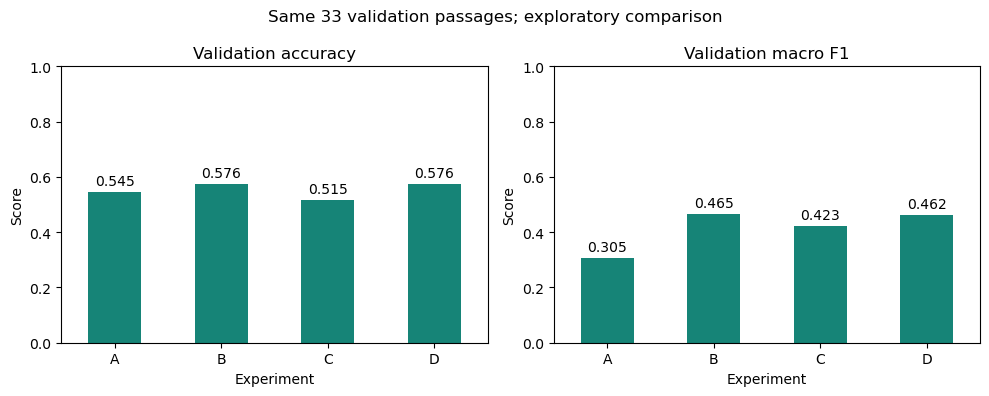

Highest saved validation macro F1: B
B correct predictions: 19 of 33


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in zip(axes, ["accuracy", "macro_f1"], ["Validation accuracy", "Validation macro F1"]):
    df[metric].plot.bar(ax=ax, color="#168477", rot=0)
    ax.set(title=title, xlabel="Experiment", ylabel="Score", ylim=(0, 1))
    for i, value in enumerate(df[metric]):
        ax.text(i, value + 0.025, f"{value:.3f}", ha="center")
fig.suptitle("Same 33 validation passages; exploratory comparison")
plt.tight_layout()
plt.show()

best = df["macro_f1"].idxmax()
print("Highest saved validation macro F1:", best)
print("B correct predictions:", round(df.loc["B", "accuracy"] * 33), "of 33")

| Experiment | Correct validation predictions | Accuracy | Macro-F1 |
|---|---:|---:|---:|
| A | 18 / 33 | 0.545455 | 0.305367 |
| B | 19 / 33 | 0.575758 | 0.464881 |
| C | 17 / 33 | 0.515152 | 0.423016 |
| D | 19 / 33 | 0.575758 | 0.461871 |

B had the highest validation macro-F1 at **0.464881**. D matched B's accuracy
and was very close in macro-F1 at **0.461871**, a difference of about **0.0030**.
Neither the smaller learning rate in C nor the longer run in D exceeded B's
selection score on this validation set.

The **0.3054** reference in the original comparison was the validation macro-F1
of the initial adapted run in notebook 06. It was not the unadapted-model
baseline or a score from the separate 35-passage test comparison.

## 3. Experiment B's Category Errors

The confusion matrix showed which categories B confused. Rows represented
the recorded reference labels, and columns represented the model's predictions.
Values on the diagonal were correct predictions. The category table reported
precision, recall, and F1 for each class.

Predicted,specific_musical_observation,general_opinion,background_other
Actual,,,
specific_musical_observation,15,2,1
general_opinion,4,2,1
background_other,6,0,2


,precision,recall,f1,support
specific_musical_observation,0.6,0.833333,0.697674,18.0
general_opinion,0.5,0.285714,0.363636,7.0
background_other,0.5,0.250000,0.333333,8.0


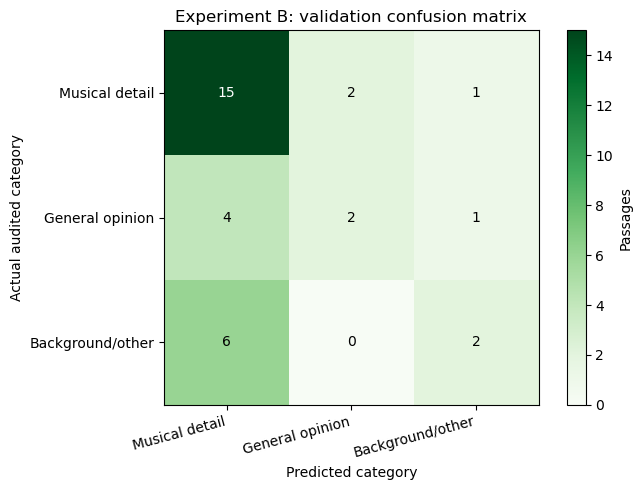

In [4]:
result = runs["B"]["selected"]["validation"]
labels = result["label_order"]
matrix = pd.DataFrame(result["confusion_matrix"], index=labels, columns=labels)
assert matrix.to_numpy().sum() == result["n"]
display(matrix.rename_axis("Actual").rename_axis("Predicted", axis=1))
display(pd.DataFrame(result["per_class"]).T)

short_labels = ["Musical detail", "General opinion", "Background/other"]
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(matrix.to_numpy(), cmap="Greens", vmin=0)
ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(short_labels, rotation=15, ha="right")
ax.set_yticklabels(short_labels)
ax.set(xlabel="Predicted category", ylabel="Actual audited category", title="Experiment B: validation confusion matrix")
for row in range(3):
    for col in range(3):
        value = matrix.iloc[row, col]
        ax.text(col, row, str(value), ha="center", va="center", color="white" if value > 8 else "black")
fig.colorbar(image, ax=ax, label="Passages")
plt.tight_layout()
plt.show()

B correctly classified **15 of 18** musical-observation passages,
**2 of 7** general opinions, and **2 of 8** background passages. It predicted
musical observations for ten passages from the other two categories.

The model handled musical observations better than general opinions or
background information. This explained why the **57.6% accuracy** did not
represent equally strong performance across all three categories.

## 4. Data Preparation and Sentiment Findings

The final summary connected the model results with the collected reviews,
cleaning decisions, and training-passage sentiment scores. The review-length
statistics described whole reviews. The model and sentiment analyses used
shorter passages prepared from those reviews.

In [5]:
word_counts = json.loads((data_dir / "word_count_summary.json").read_text())
cleaning = json.loads((data_dir / "cleaning_audit.json").read_text())
sentiment = json.loads((data_dir / "sentiment_summary.json").read_text())
print("Collected reviews:", word_counts["reviews"])
print("Average review words:", word_counts["average_words"])
print("Cleaning exclusions:", cleaning)
print("VADER training passages:", sentiment["n"])
display(pd.Series(sentiment["sign_counts"], name="Passages").to_frame())

Collected reviews: 500
Average review words: 353.518
Cleaning exclusions: {'duplicate_passage': 20, 'under_minimum_words': 217}
VADER training passages: 140


,Passages
negative_score,26
zero_score,36
positive_score,78


The dataset contained **500 reviews**, averaging **353.518 words** each.
Preparation excluded **20 duplicate passages** and **217 short passages**, leaving
**7,664 prepared passages**.

VADER, a word-based sentiment method, scored only the **140 frozen training
passages**. It produced **26 negative scores, 36 exactly zero, and 78 positive
scores**. These groups used scores below, equal to, or above zero; they did not
use the conventional ±0.05 category thresholds. A zero score did not necessarily
mean a neutral opinion. The sentiment scores described the selected training
subset and were separate from the three musical-content labels.

The sentiment analysis was added after model selection and was not used to
choose or adjust a model. Short excerpts, missing context, and music vocabulary
could affect these word-based estimates.

### Interpretation and Limitations

The model comparisons reused the same small validation set for selection and
evaluation. They supported development decisions, not an independent final test
or a significant improvement in generalization. A fresh, independently
human-labeled evaluation set would be needed to assess performance on new
passages. The bounded review sample also limited conclusions about all listeners.

### Sources

- [Training-passage VADER notebook](09_vader_sentiment_readable.ipynb)
- [VADER analysis script](../09_training_sentiment_EDA_VADER/analyze_training_vader.py)
- [Saved experiment and data summaries](../results/evidence/)
- [Original executed notebook 06](training/06_music_review_lora_AI_AUDITED_COLAB.ipynb)
- [Source attribution and notices](../THIRD_PARTY_NOTICES.md)

## Code assistance and responsibility

Generative AI assisted with pipeline and notebook code. It also helped
audit labels, suggest experiments, and debug training and diagnostics. This
results-review notebook and its explanations were prepared with AI assistance.

Aaron ran the experiments and reviewed their outputs. The
[assistance and provenance record](../packaging/AUTHORSHIP_AND_PROVENANCE.json)
and [project README](../README.md) document these contributions, the source files,
and the limits of the results.